# Notebook 2: Dự Báo Hành Vi Khách Hàng bằng Vanilla RNN

**ISD-Assignment06 | Dataset 2: Customer Rating Behavior Prediction (Vanilla RNN)**

---

| Mục | Nội dung |
|-----|----------|
| **Nguồn dữ liệu** | `data/customer_behavior/` – ratings.json, products.json, customers.json |
| **Quy mô** | 100k+ đánh giá · ~700 khách hàng · 691 sản phẩm · Giai đoạn 2018–2022 |
| **Mục tiêu** | Dự đoán `avg_rating` (điểm đánh giá trung bình toàn hệ thống) ngày tiếp theo |
| **Framework** | PyTorch + Keras (TensorFlow) |
| **Mô hình** | Vanilla RNN (PyTorch `nn.RNN` & Keras `SimpleRNN`) |
| **Metrics** | RMSE · MAE · R² |

### Chiến Lược Xây Dựng Chuỗi Thời Gian
```text
ratings.json  →  Tổng hợp theo ngày  →  18 features / ngày  →  Sliding Window(10)  →  Vanilla RNN
```

**18 Đặc trưng được thiết kế đa chiều:**
- *Thống kê hàng ngày*: `rating_count`, `avg_rating`, `unique_users`, `unique_products`, `high_ratio`, `low_ratio`, `avg_price`, `std_rating`
- *Đặc trưng xu hướng (Rolling 7D)*: `rolling_avg_7d`, `rolling_count_7d`, `rolling_std_7d`
- *Đặc trưng trễ (Lag features)*: `lag1_avg_rating`, `lag1_rating_count`, `lag7_avg_rating`
- *Mã hóa chu kỳ tuần hoàn (Cyclical Encoding)*: `dow_sin`, `dow_cos`, `month_sin`, `month_cos`


In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Thêm src vào sys.path
SRC_DIR = os.path.join('..', 'src')
sys.path.insert(0, SRC_DIR)

from data_generator import load_customer_behavior_data
import customer_pytorch as pt
import customer_keras as ks

# Dark theme cho biểu đồ
plt.style.use('dark_background')
plt.rcParams.update({'figure.figsize': (14, 5), 'font.family': 'DejaVu Sans'})
%matplotlib inline

print('Import thành công các thư viện!')
print(f'   PyTorch device : {pt.DEVICE}')

[Customer PyTorch] Device: cpu
[Customer Keras] TF 2.21.0 | GPU: 0
Import thành công các thư viện!
   PyTorch device : cpu


---
## Phần 1: Khám Phá Dữ Liệu (EDA)

In [2]:
# ── Load & Aggregate dữ liệu theo ngày ──
data = load_customer_behavior_data(
    window_size  = 10,
    train_ratio  = 0.8,
    aggregation  = 'daily'
)

stats      = data['stats']
df_agg     = data['df_agg']
df_ratings = data['df_ratings']

print('Thông tin Dataset Hành Vi Khách Hàng (Customer Behavior):')
print('-' * 55)
for k, v in stats.items():
    print(f'   {k:<28} : {v}')
print()
print(f'   X_train shape : {data["X_train"].shape}')
print(f'   X_test  shape : {data["X_test"].shape}')
print(f'   Features ({stats["n_features"]}) : {data["feature_names"]}')

[CustomerData] Đang tải ratings.json ...
[CustomerData] Đang tải products.json ...
[CustomerData] Đang tải customers.json ...
[CustomerData] Tổng ratings: 130,754 | Khách hàng: 344 | Sản phẩm: 691 | Khoảng thời gian: 2018-01-01 → 2022-03-16
[CustomerData] Chuỗi thời gian daily: 1529 mẫu | Train: 1213 | Test: 296 | Features: 18 | Window: 10
Thông tin Dataset Hành Vi Khách Hàng (Customer Behavior):
-------------------------------------------------------
   total_ratings                : 130754
   total_customers              : 344
   total_products               : 691
   date_range                   : 2018-01-01 → 2022-03-16
   avg_rating_global            : 3.189
   n_periods                    : 1529
   train_samples                : 1213
   test_samples                 : 296
   n_features                   : 18

   X_train shape : (1213, 10, 18)
   X_test  shape : (296, 10, 18)
   Features (18) : ['rating_count', 'avg_rating', 'unique_users', 'unique_products', 'high_ratio', 'low_rati

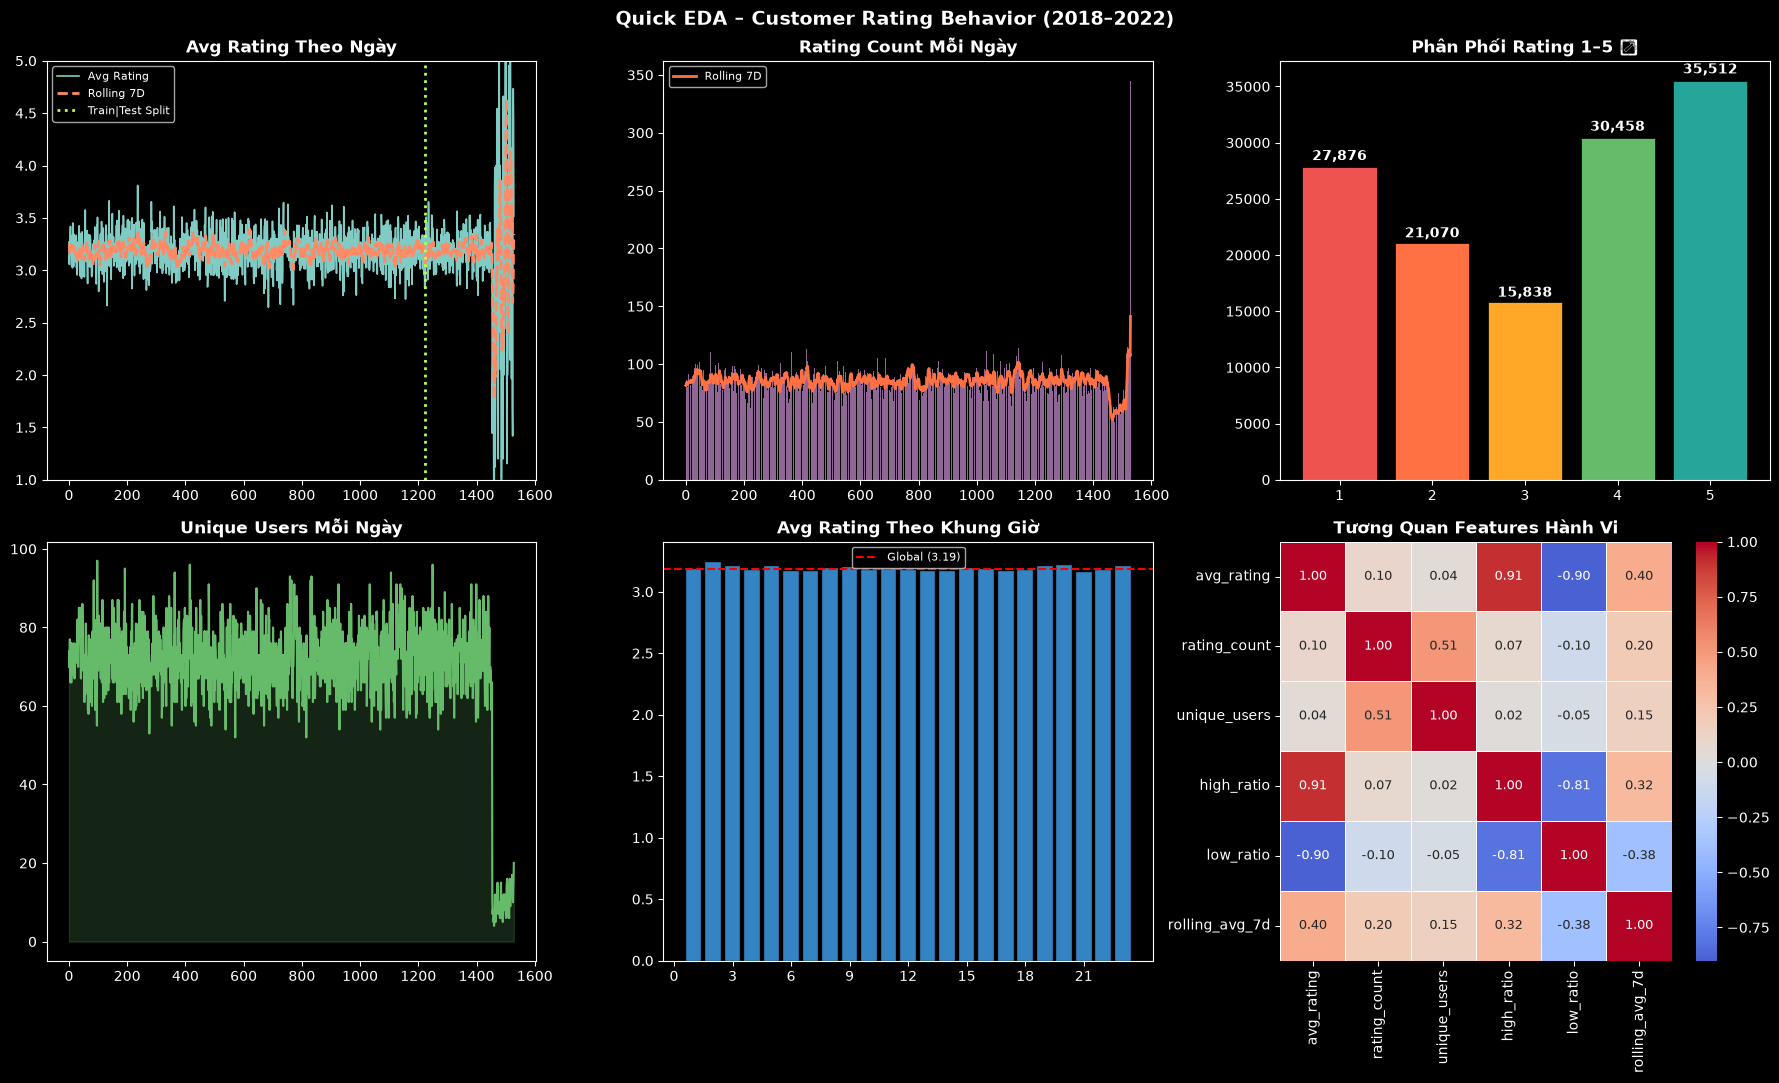

Toàn bộ 8 panel EDA đã sẵn sàng trong reports/figures/.


In [3]:
# ── EDA Inline: Tổng quan dữ liệu hành vi ──
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle('Quick EDA – Customer Rating Behavior (2018–2022)', fontsize=14, fontweight='bold')

# 1. Điểm rating trung bình theo ngày & Rolling 7D
ax = axes[0, 0]
ax.plot(df_agg.index, df_agg['avg_rating'], '#80CBC4', lw=1.2, label='Avg Rating')
ax.plot(df_agg.index, df_agg['rolling_avg_7d'], '#FF8A65', lw=2.0, ls='--', label='Rolling 7D')
ax.axvline(data['train_size'], color='#B2FF59', lw=2, ls=':', label='Train|Test Split')
ax.set_ylim(1, 5); ax.set_title('Avg Rating Theo Ngày', fontweight='bold'); ax.legend(fontsize=8)

# 2. Số lượng đánh giá (Rating Count)
ax = axes[0, 1]
ax.bar(df_agg.index, df_agg['rating_count'], color='#CE93D8', alpha=0.7, width=0.8)
ax.plot(df_agg.index, df_agg['rolling_count_7d'], '#FF7043', lw=2.0, label='Rolling 7D')
ax.set_title('Rating Count Mỗi Ngày', fontweight='bold'); ax.legend(fontsize=8)

# 3. Phân phối rating 1–5 sao
ax = axes[0, 2]
rc = df_ratings['Rate'].value_counts().sort_index()
ax.bar(rc.index, rc.values,
       color=['#EF5350','#FF7043','#FFA726','#66BB6A','#26A69A'],
       edgecolor='black', lw=0.5)
for x_pos, v in zip(rc.index, rc.values):
    ax.text(x_pos, v * 1.01, f'{v:,}', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_xticks([1,2,3,4,5]); ax.set_title('Phân Phối Rating 1–5 ⭐', fontweight='bold')

# 4. Người dùng duy nhất (Unique Users)
ax = axes[1, 0]
ax.plot(df_agg.index, df_agg['unique_users'], '#66BB6A', lw=1.5)
ax.fill_between(df_agg.index, 0, df_agg['unique_users'], alpha=0.2, color='#66BB6A')
ax.set_title('Unique Users Mỗi Ngày', fontweight='bold')

# 5. Rating theo khung giờ
ax = axes[1, 1]
df_ratings['hour'] = df_ratings['CreateDate'].dt.hour
hourly = df_ratings.groupby('hour')['Rate'].mean()
ax.bar(hourly.index, hourly.values, color='#42A5F5', alpha=0.8, edgecolor='black', lw=0.3)
ax.axhline(df_ratings['Rate'].mean(), color='red', ls='--', lw=1.5, label=f'Global ({df_ratings["Rate"].mean():.2f})')
ax.set_xticks(range(0, 24, 3))
ax.set_title('Avg Rating Theo Khung Giờ', fontweight='bold'); ax.legend(fontsize=8)

# 6. Ma trận tương quan đặc trưng
ax = axes[1, 2]
cols = ['avg_rating','rating_count','unique_users','high_ratio','low_ratio','rolling_avg_7d']
sns.heatmap(df_agg[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            ax=ax, center=0, linewidths=0.5, annot_kws={'size': 9})
ax.set_title('Tương Quan Features Hành Vi', fontweight='bold')

plt.tight_layout(); plt.show()
print('Toàn bộ 8 panel EDA đã sẵn sàng trong reports/figures/.')

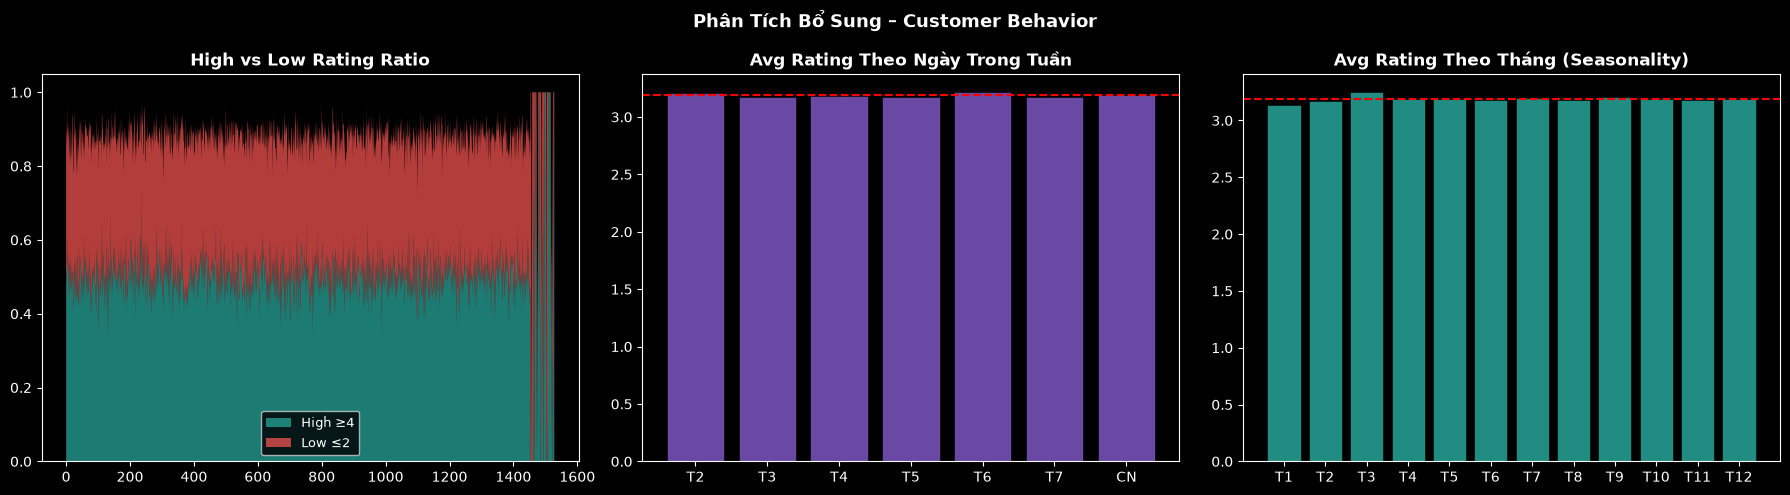

In [4]:
# ── Phân tích bổ sung: High/Low ratio & Tính chu kỳ (Seasonality) ──
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Phân Tích Bổ Sung – Customer Behavior', fontsize=13, fontweight='bold')

# 1. High vs Low rating ratio
ax = axes[0]
ax.stackplot(df_agg.index, df_agg['high_ratio'], df_agg['low_ratio'],
             colors=['#26A69A','#EF5350'], alpha=0.75, labels=['High ≥4','Low ≤2'])
ax.set_title('High vs Low Rating Ratio', fontweight='bold'); ax.legend(fontsize=9)

# 2. Rating theo ngày trong tuần
ax = axes[1]
df_ratings['dayofweek'] = df_ratings['CreateDate'].dt.dayofweek
dow_labels = ['T2','T3','T4','T5','T6','T7','CN']
dow_avg = df_ratings.groupby('dayofweek')['Rate'].mean()
ax.bar(dow_labels, dow_avg.values, color='#7E57C2', alpha=0.85, edgecolor='black', lw=0.5)
ax.axhline(df_ratings['Rate'].mean(), color='red', ls='--', lw=1.5)
ax.set_title('Avg Rating Theo Ngày Trong Tuần', fontweight='bold')

# 3. Rating theo tháng trong năm
ax = axes[2]
df_ratings['month'] = df_ratings['CreateDate'].dt.month
month_labels = ['T1','T2','T3','T4','T5','T6','T7','T8','T9','T10','T11','T12']
month_avg = df_ratings.groupby('month')['Rate'].mean()
ax.bar(month_labels, month_avg.values, color='#26A69A', alpha=0.85, edgecolor='black', lw=0.5)
ax.axhline(df_ratings['Rate'].mean(), color='red', ls='--', lw=1.5)
ax.set_title('Avg Rating Theo Tháng (Seasonality)', fontweight='bold')

plt.tight_layout(); plt.show()

---
## Phần 2: PyTorch Pipeline – Vanilla RNN

**Kiến trúc `CustomerRNNModel` (Vanilla RNN):**
```text
[Input (B, 10, 18)] → [Vanilla RNN (nn.RNN) × 2 layers, hidden=64] → Dropout(0.2)
                     → [Linear(64 → 32) → ReLU → Dropout(0.2)]
                     → [Linear(32 → 16) → ReLU]
                     → [Linear(16 → 1)]  # Dự đoán avg_rating ngày tiếp theo
```
**Kỹ thuật:** Gradient Clipping (`max_norm=1.0`) · ReduceLROnPlateau · Time-based Split không xáo trộn.

In [5]:
# ── Huấn luyện Vanilla RNN bằng PyTorch ──
pytorch_results = pt.run_pipeline(
    window_size = 10,
    epochs      = 60,
    batch_size  = 32,
    hidden_dim  = 64,
    train_ratio = 0.8,
    aggregation = 'daily',
)


  PYTORCH CUSTOMER PIPELINE (RNN - DAILY)
[CustomerData] Đang tải ratings.json ...
[CustomerData] Đang tải products.json ...
[CustomerData] Đang tải customers.json ...
[CustomerData] Tổng ratings: 130,754 | Khách hàng: 344 | Sản phẩm: 691 | Khoảng thời gian: 2018-01-01 → 2022-03-16
[CustomerData] Chuỗi thời gian daily: 1529 mẫu | Train: 1213 | Test: 296 | Features: 18 | Window: 10

[EDA] Đang vẽ biểu đồ phân tích...
[OK] EDA → G:\Workplace\ISD-Assignment06\notebooks\..\src\..\reports\figures\customer_eda_pytorch.png

  [Train] RNN (Vanilla RNN)...
  [010/60] Train: 0.021742 | Val: 0.370903
  [020/60] Train: 0.020762 | Val: 0.369513
  [030/60] Train: 0.020875 | Val: 0.370983
  [040/60] Train: 0.020554 | Val: 0.370230
  [050/60] Train: 0.020306 | Val: 0.370380
  [060/60] Train: 0.020426 | Val: 0.370371
  → RMSE: 0.6551 | MAE: 0.3816 | R²: -0.0026
[OK] RNN → G:\Workplace\ISD-Assignment06\notebooks\..\src\..\reports\figures\customer_rnn_pytorch.png

───────────────────────────────────────

EDA – Hành Vi Khách Hàng (PyTorch):


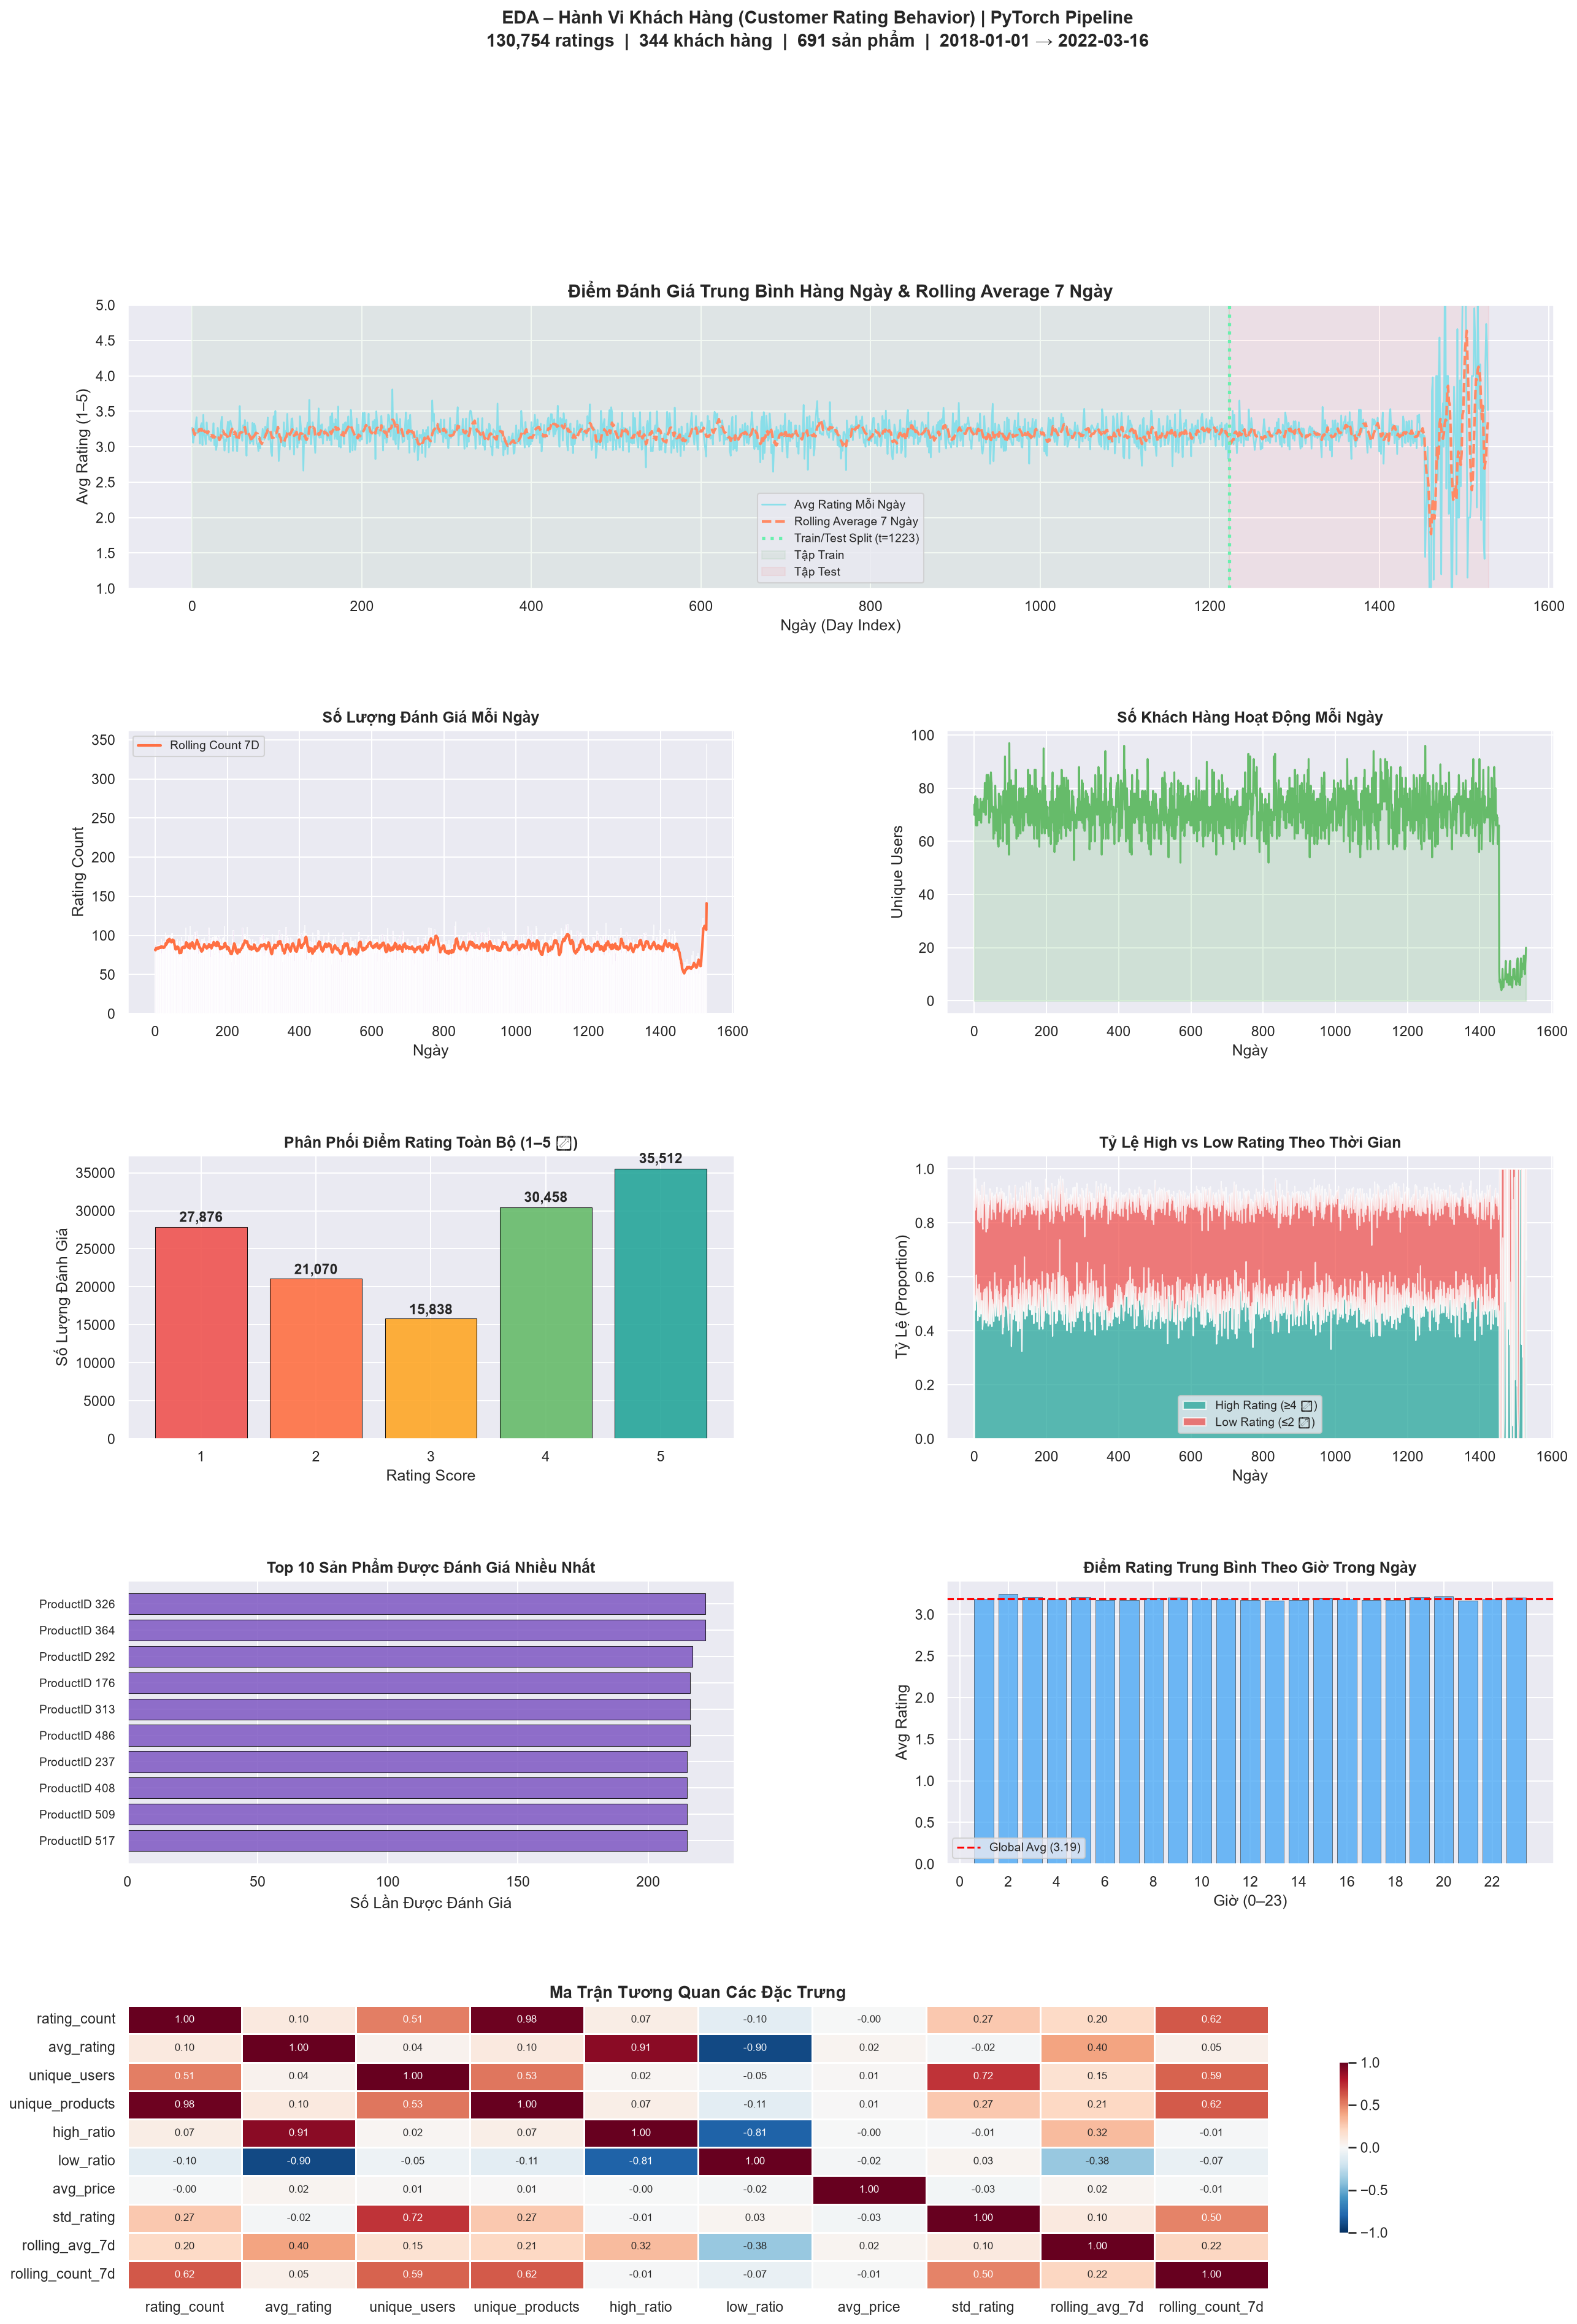

Kết Quả Huấn Luyện PyTorch Vanilla RNN:


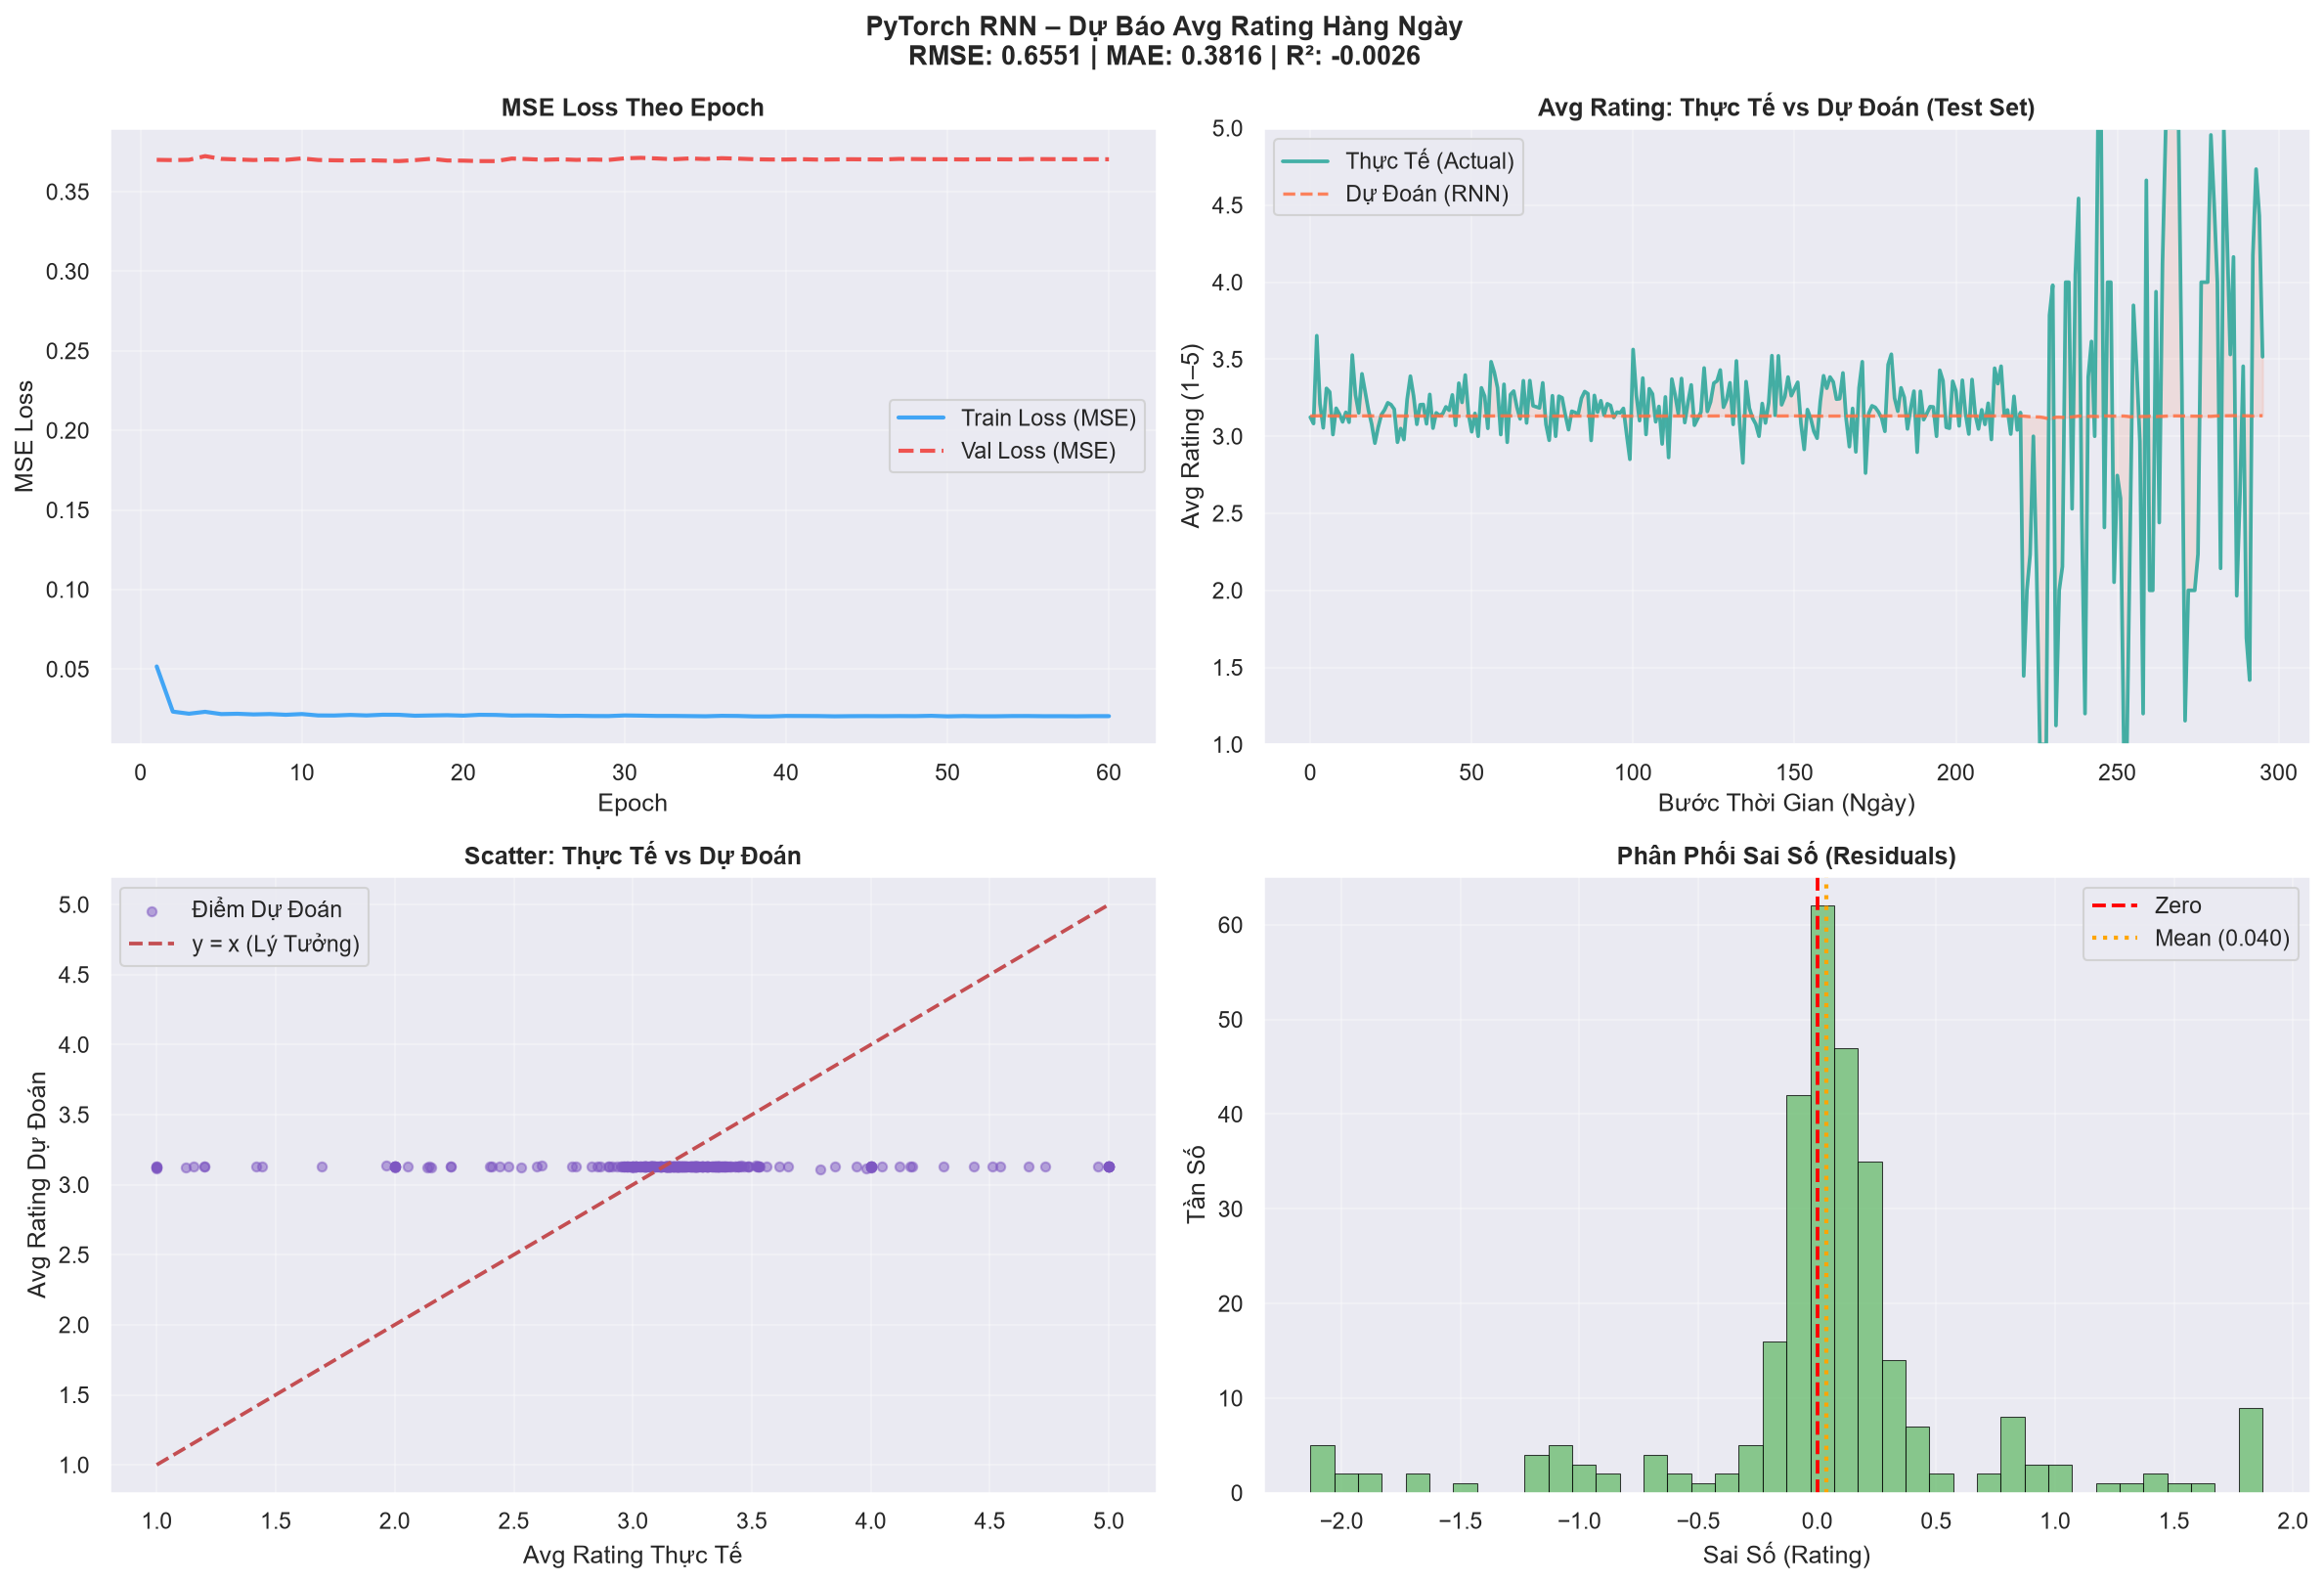

In [6]:
# ── Hiển thị biểu đồ PyTorch Vanilla RNN ──
from IPython.display import Image, display
FIG_DIR = os.path.join('..', 'reports', 'figures')

# 1. EDA 8-panel
eda_path = os.path.join(FIG_DIR, 'customer_eda_pytorch.png')
if os.path.exists(eda_path):
    print('EDA – Hành Vi Khách Hàng (PyTorch):')
    display(Image(filename=eda_path, width=950))

# 2. Kết quả Vanilla RNN
rnn_path = os.path.join(FIG_DIR, 'customer_rnn_pytorch.png')
if os.path.exists(rnn_path):
    print('Kết Quả Huấn Luyện PyTorch Vanilla RNN:')
    display(Image(filename=rnn_path, width=950))

---
## Phần 3: Keras Pipeline – SimpleRNN

**Kiến trúc `build_model` (Vanilla SimpleRNN):**
```text
[SimpleRNN(64 units, return_sequences=True)] → Dropout(0.2) → BatchNorm
[SimpleRNN(32 units, return_sequences=False)] → Dropout(0.2) → BatchNorm
Dense(32, activation='relu') → Dropout(0.1) → Dense(16, activation='relu') → Dense(1)
```
**Callbacks:** `EarlyStopping(patience=12, restore_best_weights=True)` · `ReduceLROnPlateau(factor=0.5, patience=6)`

In [7]:
# ── Huấn luyện SimpleRNN bằng Keras / TensorFlow ──
keras_results = ks.run_pipeline(
    window_size     = 10,
    epochs          = 80,
    batch_size      = 32,
    units           = 64,
    train_ratio     = 0.8,
    aggregation     = 'daily',
    pytorch_results = pytorch_results,   # Đối đầu trực tiếp với PyTorch
)


  KERAS CUSTOMER PIPELINE (RNN - DAILY)
[CustomerData] Đang tải ratings.json ...
[CustomerData] Đang tải products.json ...
[CustomerData] Đang tải customers.json ...
[CustomerData] Tổng ratings: 130,754 | Khách hàng: 344 | Sản phẩm: 691 | Khoảng thời gian: 2018-01-01 → 2022-03-16
[CustomerData] Chuỗi thời gian daily: 1529 mẫu | Train: 1213 | Test: 296 | Features: 18 | Window: 10

[EDA] Đang vẽ biểu đồ phân tích...
[OK] EDA → G:\Workplace\ISD-Assignment06\notebooks\..\src\..\reports\figures\customer_eda_keras.png

  [Train] Keras RNN (SimpleRNN)...


Model: "RNN_customer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ RNN_1 (SimpleRNN)                    │ (None, 10, 64)              │           5,312 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 10, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 10, 64)              │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ RNN_2 (SimpleRNN)                    │ (None, 32)                  │           3,104 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 32)                  │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │           1,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output (Dense)                       │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 10,401 (40.63 KB)

 Trainable params: 10,209 (39.88 KB)

 Non-trainable params: 192 (768.00 B)


Epoch 19: ReduceLROnPlateau reducing learning rate to 0.0010000000474974513.

Epoch 25: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
Epoch 25: early stopping
Restoring model weights from the end of the best epoch: 13.
  → RMSE: 0.6507 | MAE: 0.3774 | R²: 0.0109
[OK] RNN → G:\Workplace\ISD-Assignment06\notebooks\..\src\..\reports\figures\customer_rnn_keras.png
[OK] Framework comparison → G:\Workplace\ISD-Assignment06\notebooks\..\src\..\reports\figures\customer_framework.png

───────────────────────────────────────────────────────
  KẾT QUẢ KERAS (RNN) – Hành Vi Khách Hàng
───────────────────────────────────────────────────────
  Model          RMSE        MAE         R²
  ──────────────────────────────────────────
  RNN          0.6507     0.3774     0.0109


EDA – Hành Vi Khách Hàng (Keras):


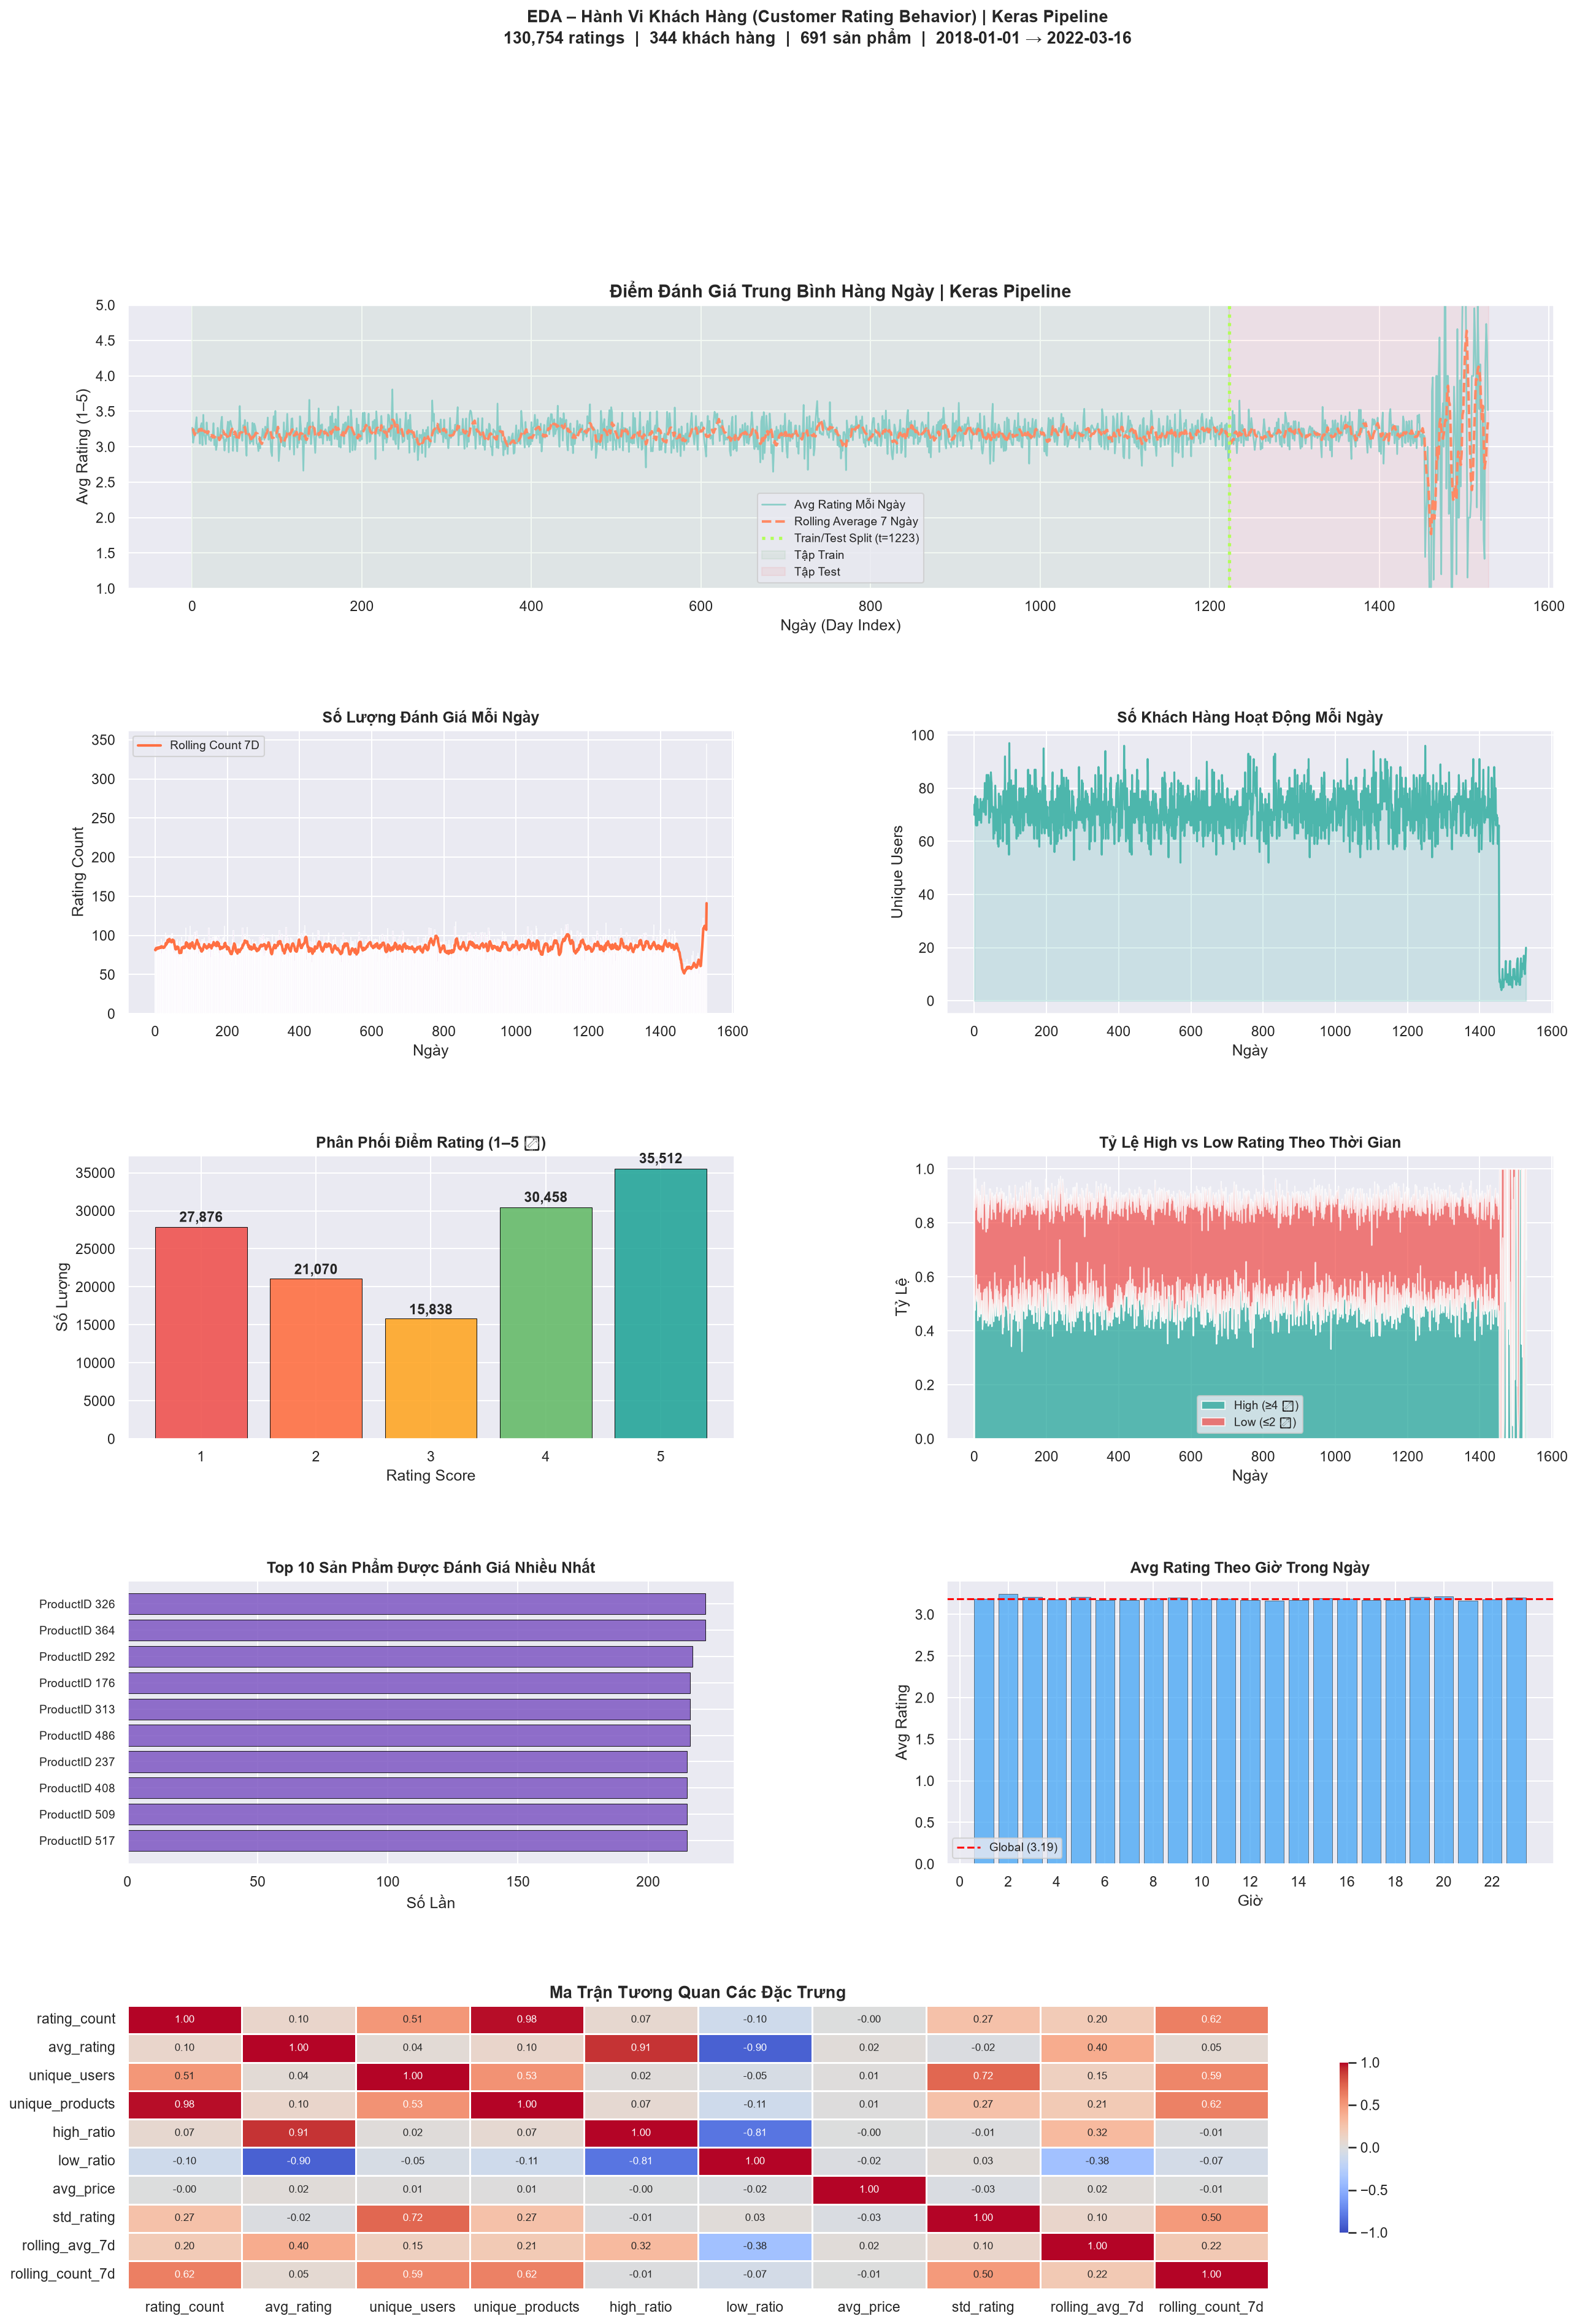

Kết Quả Huấn Luyện Keras SimpleRNN:


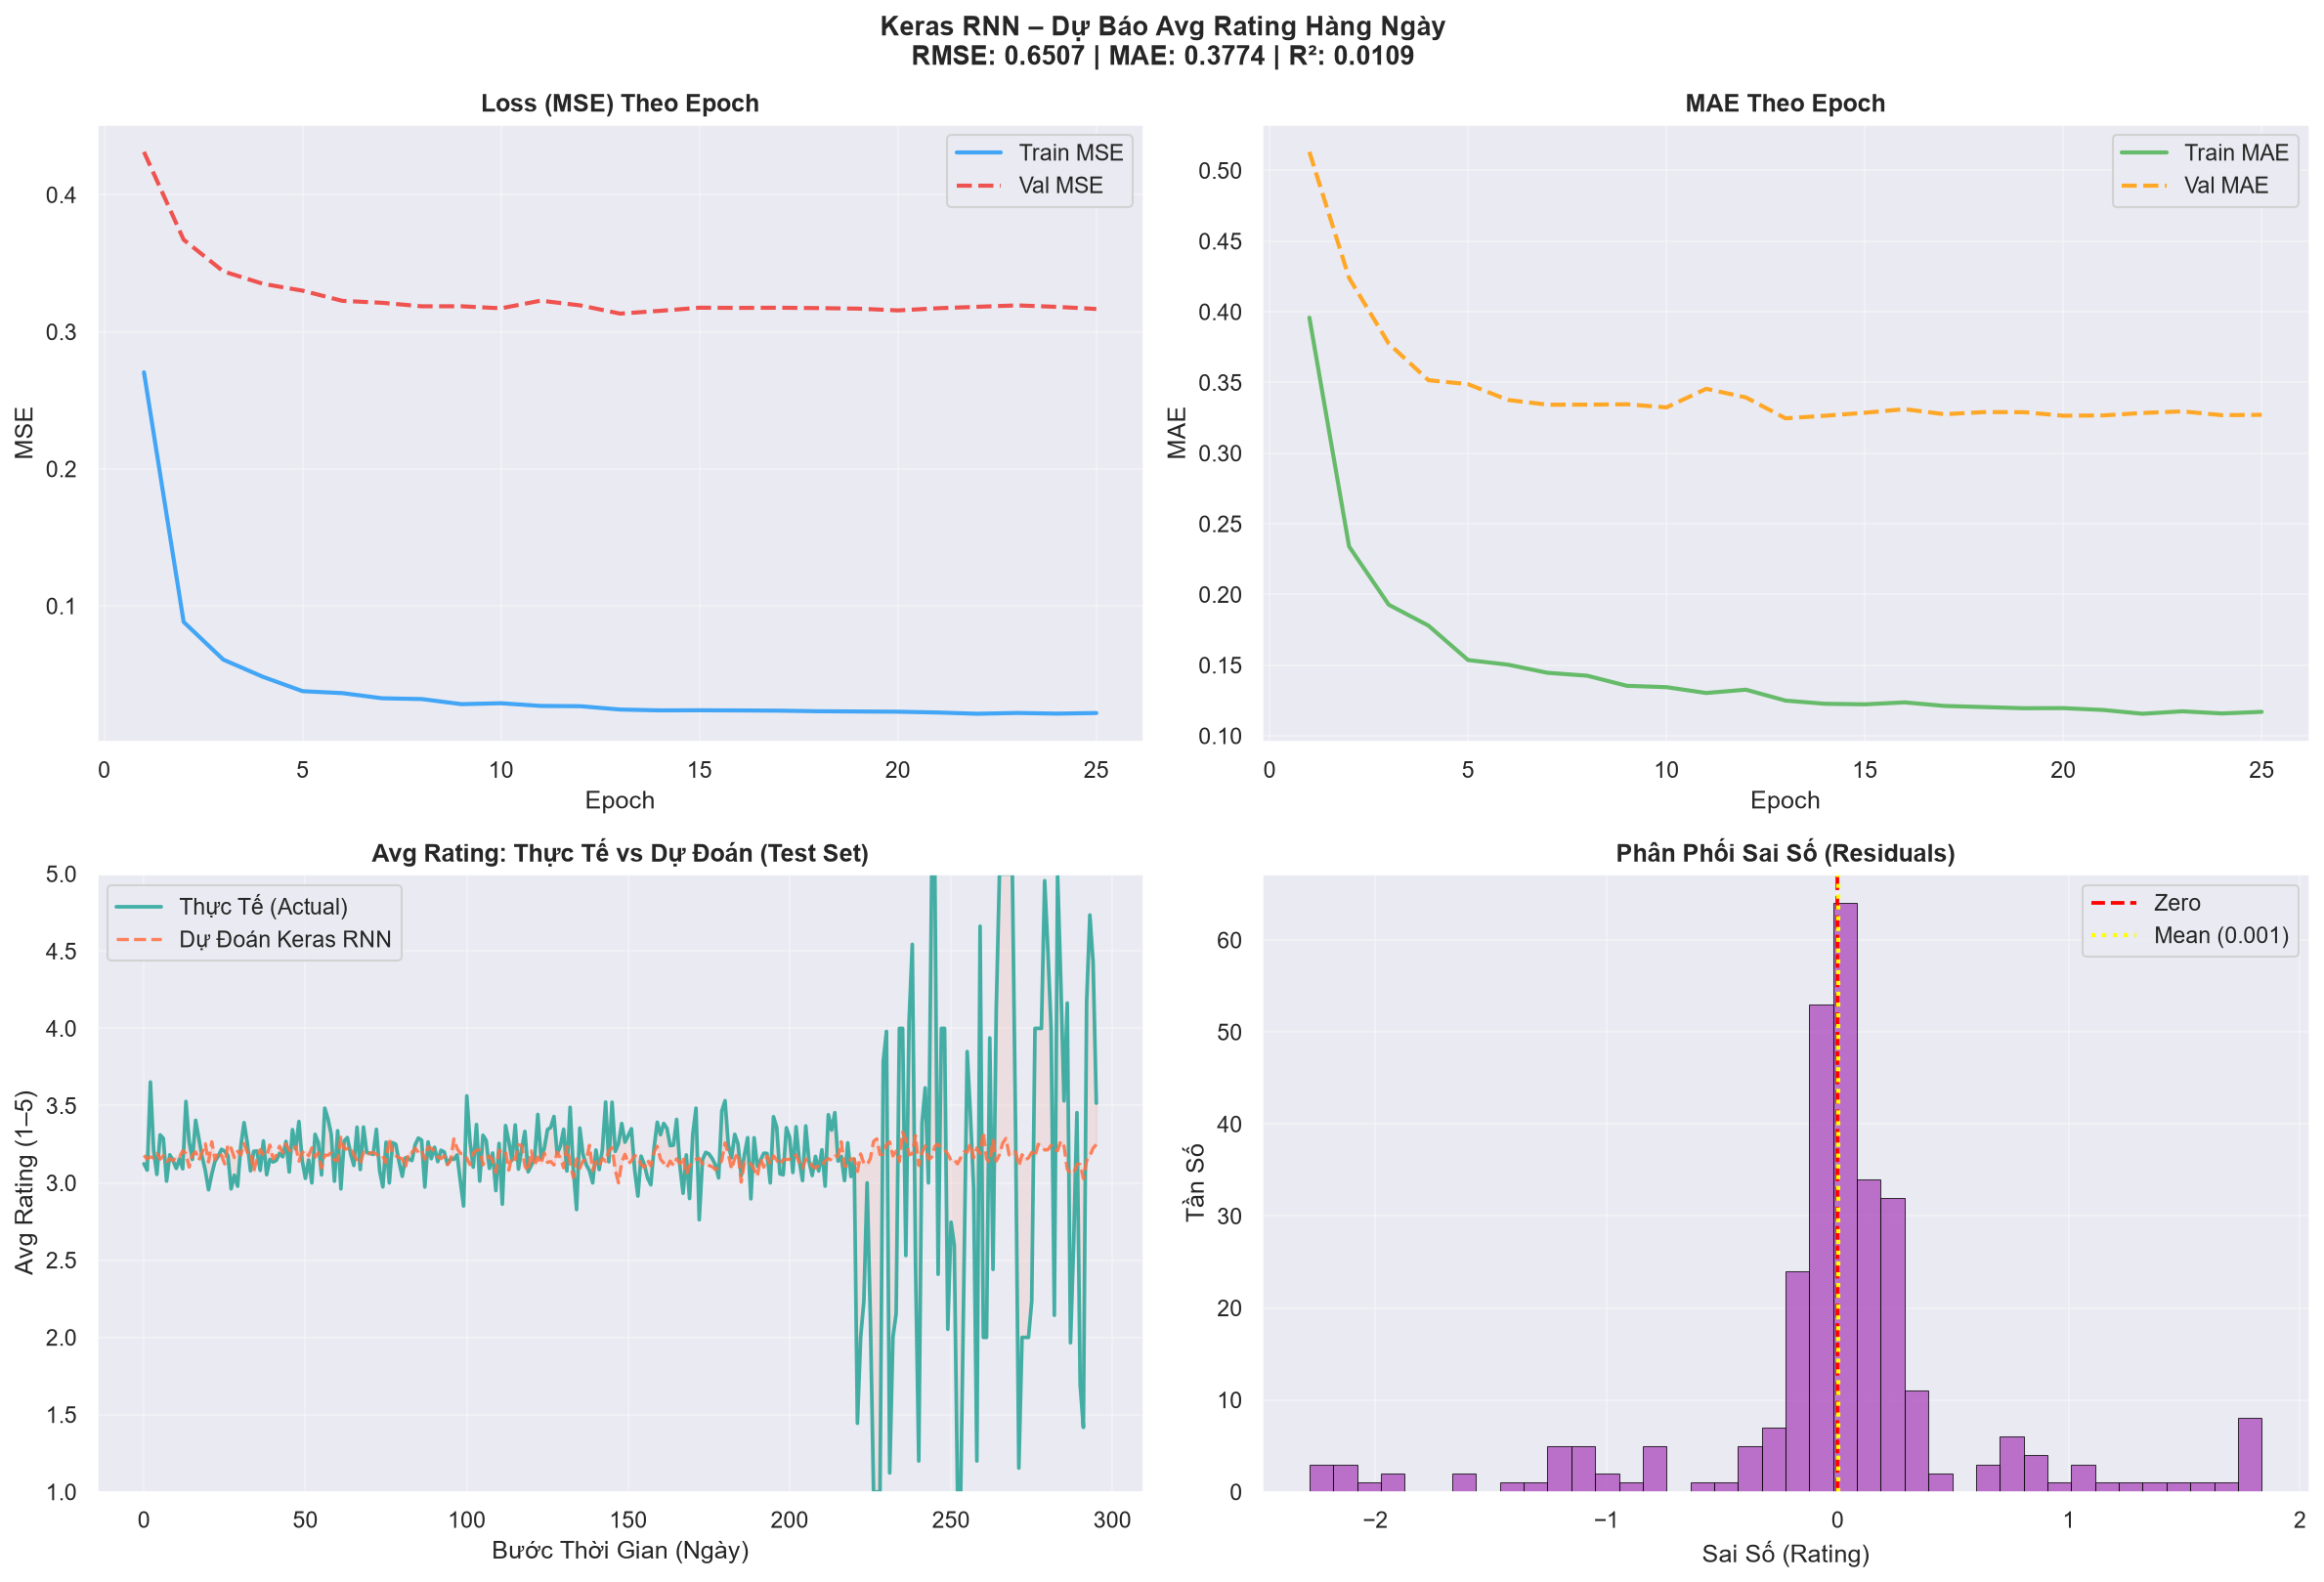

In [8]:
# ── Hiển thị biểu đồ Keras SimpleRNN ──
eda_k_path = os.path.join(FIG_DIR, 'customer_eda_keras.png')
if os.path.exists(eda_k_path):
    print('EDA – Hành Vi Khách Hàng (Keras):')
    display(Image(filename=eda_k_path, width=950))

rnn_k_path = os.path.join(FIG_DIR, 'customer_rnn_keras.png')
if os.path.exists(rnn_k_path):
    print('Kết Quả Huấn Luyện Keras SimpleRNN:')
    display(Image(filename=rnn_k_path, width=950))

---
## Phần 4: So Sánh Framework PyTorch vs Keras (Vanilla RNN)

Đối Đầu Framework: PyTorch RNN vs Keras RNN:


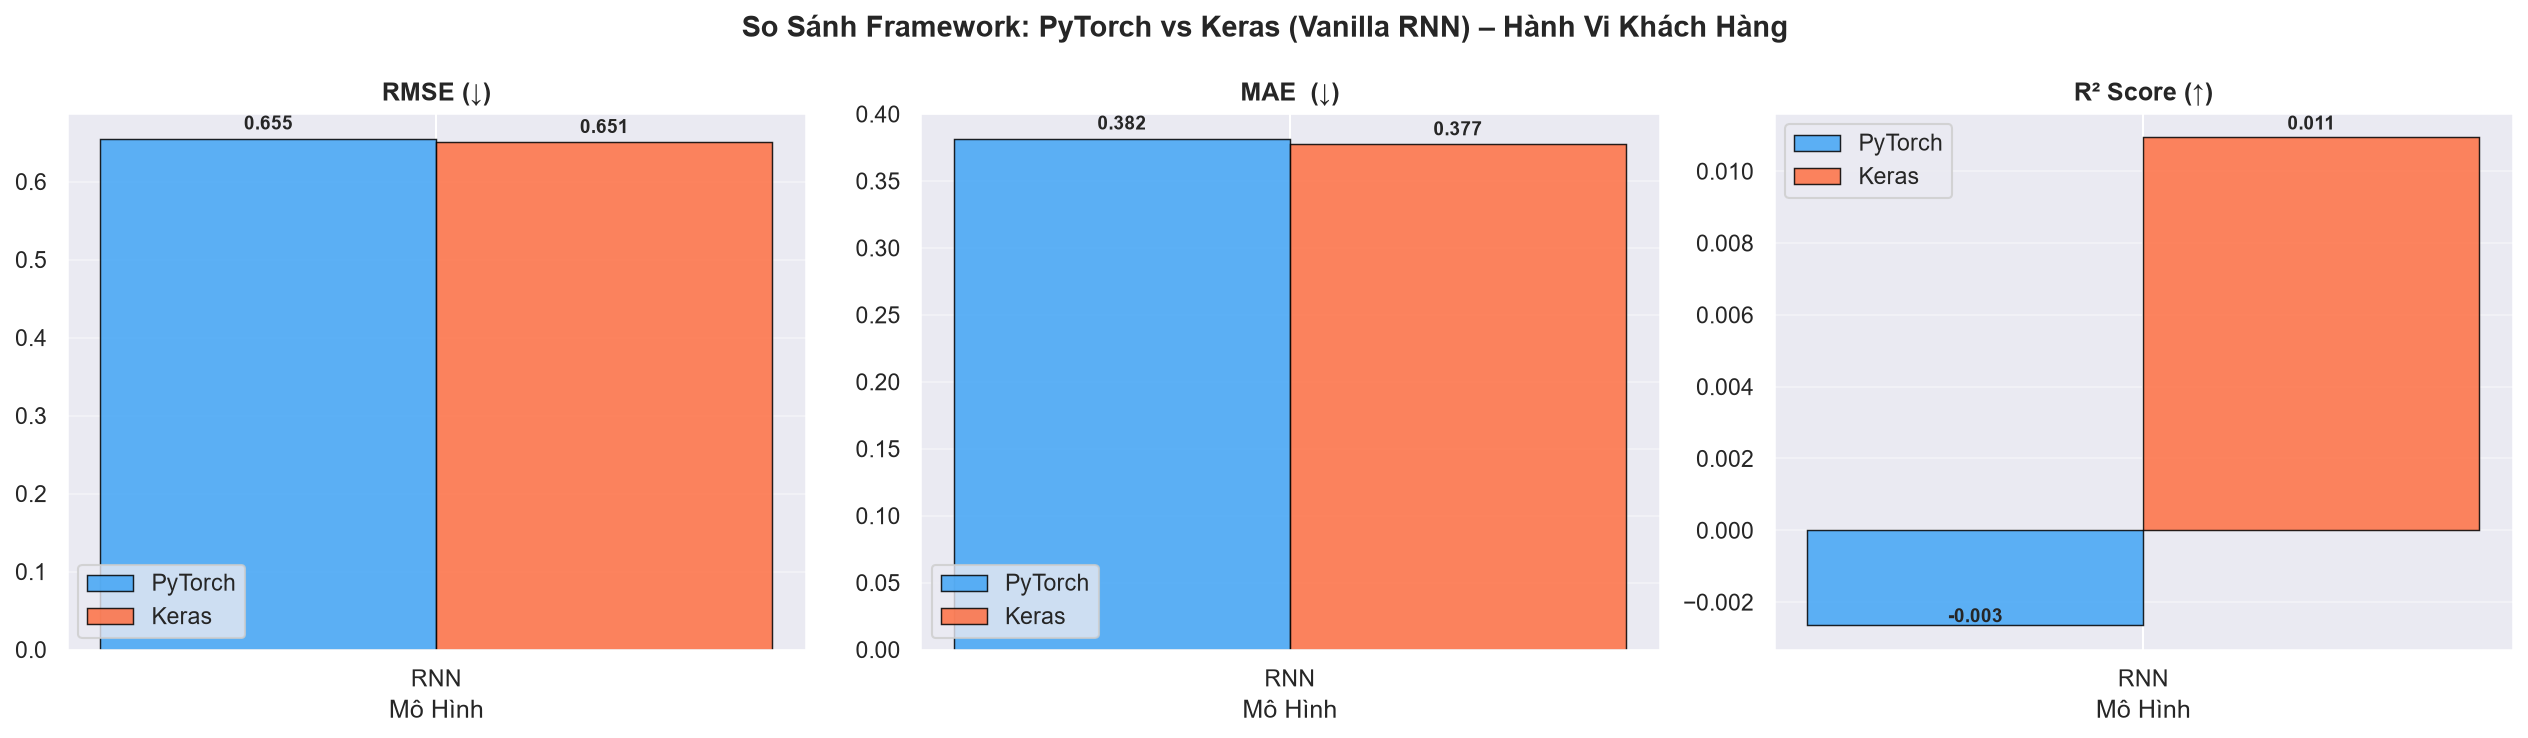

In [9]:
# ── Biểu đồ so sánh đối đầu PyTorch RNN vs Keras RNN ──
fw_path = os.path.join(FIG_DIR, 'customer_framework.png')
if os.path.exists(fw_path):
    print('Đối Đầu Framework: PyTorch RNN vs Keras RNN:')
    display(Image(filename=fw_path, width=950))

In [10]:
# ── Bảng tổng hợp số liệu ──
print('=' * 60)
print('  BẢNG TỔNG HỢP HIỆU NĂNG VANILLA RNN – HÀNH VI KHÁCH HÀNG')
print('=' * 60)
print(f'  {"Framework":<12} {"Model":<12} {"RMSE":>10} {"MAE":>10} {"R²":>10}')
print('  ' + '─' * 50)
for m, r in pytorch_results.items():
    print(f'  {"PyTorch":<12} {m:<12} {r["rmse"]:>10.4f} {r["mae"]:>10.4f} {r["r2"]:>10.4f}')
for m, r in keras_results.items():
    print(f'  {"Keras":<12} {m:<12} {r["rmse"]:>10.4f} {r["mae"]:>10.4f} {r["r2"]:>10.4f}')
print('=' * 60)

# So sánh framework nào tối ưu hơn
pt_rmse = pytorch_results['RNN']['rmse']
ks_rmse = keras_results['RNN']['rmse']
best_fw = 'PyTorch' if pt_rmse < ks_rmse else 'Keras'
diff = abs(pt_rmse - ks_rmse)
print(f'  Framework đạt RMSE thấp hơn: {best_fw} (chênh lệch: {diff:.4f})')

  BẢNG TỔNG HỢP HIỆU NĂNG VANILLA RNN – HÀNH VI KHÁCH HÀNG
  Framework    Model              RMSE        MAE         R²
  ──────────────────────────────────────────────────
  PyTorch      RNN              0.6551     0.3816    -0.0026
  Keras        RNN              0.6507     0.3774     0.0109
  Framework đạt RMSE thấp hơn: Keras (chênh lệch: 0.0045)


---
## Phần 5: Phân Tích Chuyên Sâu

In [11]:
# ── Thống kê hoạt động của User và Phân phối Sản Phẩm ──
print('Thống kê hoạt động người dùng và sản phẩm:')
print()
user_counts = df_ratings.groupby('CustomerID').size()
print(f'  Ratings trung bình / khách hàng : {user_counts.mean():.1f}')
print(f'  Số user có ít nhất 10 ratings   : {(user_counts >= 10).sum()}')
print(f'  Số user có ít nhất 50 ratings   : {(user_counts >= 50).sum()}')
print()

prod_counts = df_ratings.groupby('ProductID').size()
print(f'  Ratings trung bình / sản phẩm   : {prod_counts.mean():.1f}')
print(f'  Top 5 sản phẩm nhận nhiều đánh giá nhất:')
for pid, cnt in prod_counts.nlargest(5).items():
    prod_info = data['df_products'][data['df_products']['ProductID']==pid]
    name = prod_info['ProductName'].values[0][:40] if len(prod_info) > 0 else 'Unknown'
    print(f'    [ID {pid:3d}] {name}... : {cnt} ratings')

Thống kê hoạt động người dùng và sản phẩm:

  Ratings trung bình / khách hàng : 380.1
  Số user có ít nhất 10 ratings   : 344
  Số user có ít nhất 50 ratings   : 344

  Ratings trung bình / sản phẩm   : 189.2
  Top 5 sản phẩm nhận nhiều đánh giá nhất:
    [ID 326] White Lab-Created Sapphire Ring Pear/Rou... : 222 ratings
    [ID 364] Neil Lane Ruby Anniversary Band 1/6 ct t... : 222 ratings
    [ID 292] Le Vian Men's Diamond Ring 7/8 ct tw 14K... : 217 ratings
    [ID 176] Set inox straw... : 216 ratings
    [ID 313] Le Vian Chocolate Quartz Ring 1/4 ct tw ... : 216 ratings


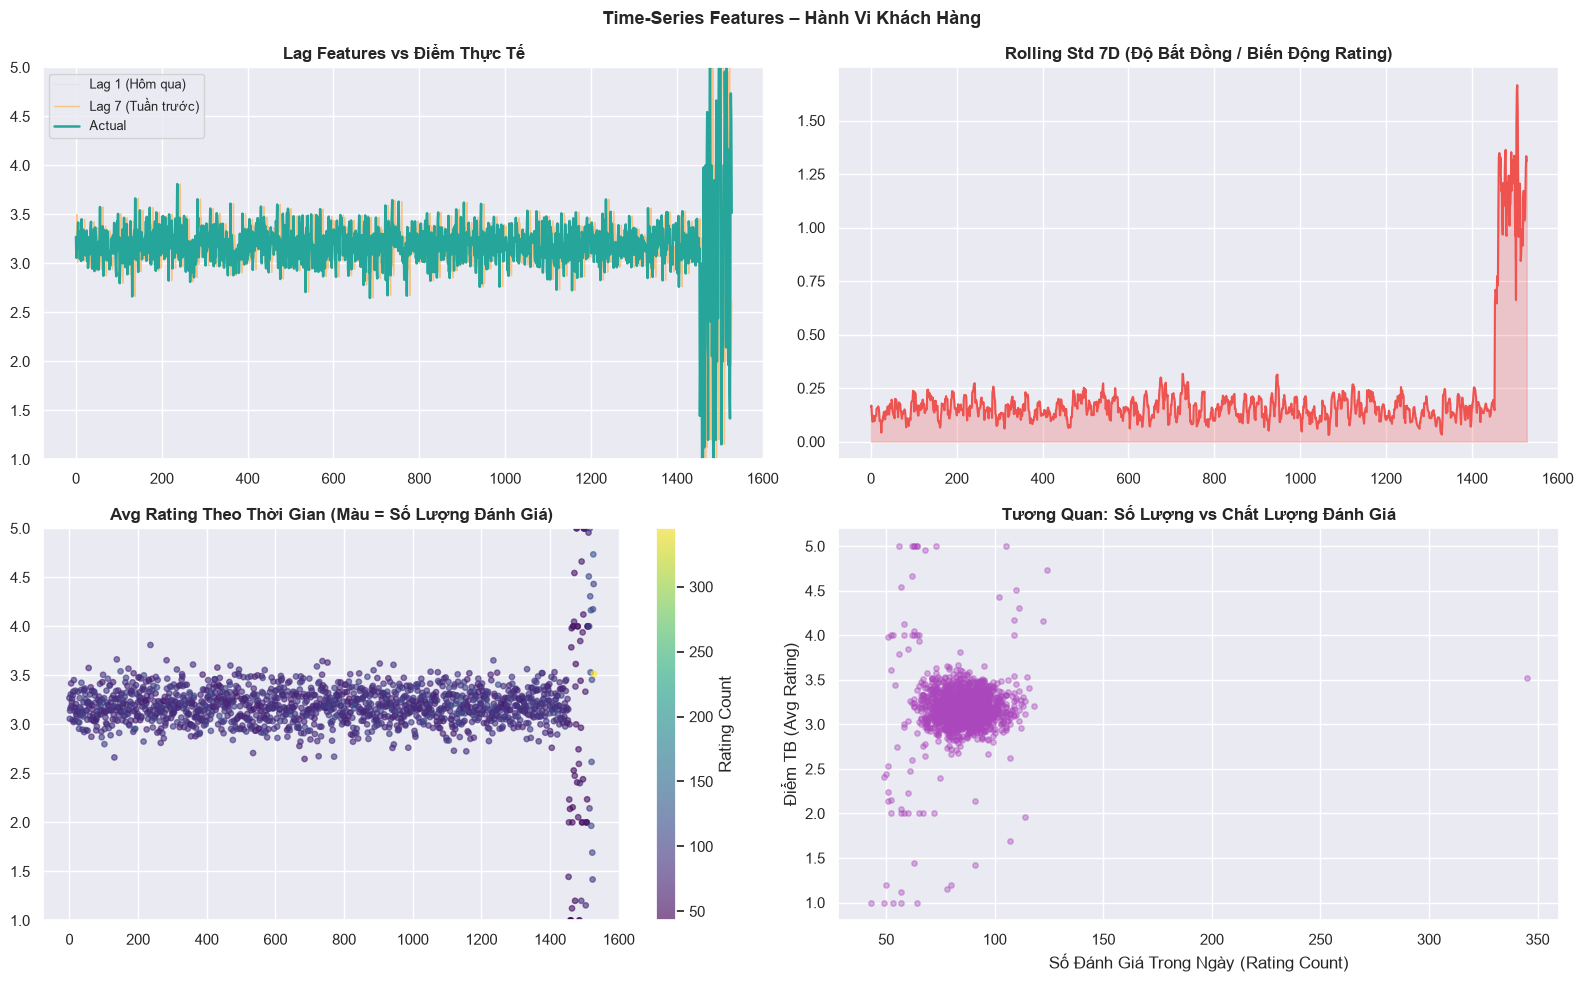

In [12]:
# ── Trực quan hóa tương quan chuỗi thời gian của các đặc trưng ──
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Time-Series Features – Hành Vi Khách Hàng', fontsize=13, fontweight='bold')

# 1. Lag 1, Lag 7 vs Actual
ax = axes[0, 0]
ax.plot(df_agg.index, df_agg['lag1_avg_rating'], '#E0E0E0', lw=1.0, alpha=0.6, label='Lag 1 (Hôm qua)')
ax.plot(df_agg.index, df_agg['lag7_avg_rating'], '#FFAB40', lw=1.0, alpha=0.6, label='Lag 7 (Tuần trước)')
ax.plot(df_agg.index, df_agg['avg_rating'],      '#26A69A', lw=1.8, label='Actual')
ax.set_ylim(1, 5); ax.set_title('Lag Features vs Điểm Thực Tế', fontweight='bold'); ax.legend(fontsize=9)

# 2. Rolling Standard Deviation 7D
ax = axes[0, 1]
ax.plot(df_agg.index, df_agg['rolling_std_7d'], '#EF5350', lw=1.5)
ax.fill_between(df_agg.index, 0, df_agg['rolling_std_7d'], alpha=0.25, color='#EF5350')
ax.set_title('Rolling Std 7D (Độ Bất Đồng / Biến Động Rating)', fontweight='bold')

# 3. Scatter plot: Avg Rating vs Rating Count theo thời gian
ax = axes[1, 0]
sc = ax.scatter(df_agg.index, df_agg['avg_rating'],
                c=df_agg['rating_count'], cmap='viridis',
                s=15, alpha=0.6)
plt.colorbar(sc, ax=ax, label='Rating Count')
ax.set_ylim(1, 5)
ax.set_title('Avg Rating Theo Thời Gian (Màu = Số Lượng Đánh Giá)', fontweight='bold')

# 4. Correlation: Số lượng vs Điểm trung bình
ax = axes[1, 1]
ax.scatter(df_agg['rating_count'], df_agg['avg_rating'],
           alpha=0.4, s=15, color='#AB47BC')
ax.set_xlabel('Số Đánh Giá Trong Ngày (Rating Count)'); ax.set_ylabel('Điểm TB (Avg Rating)')
ax.set_title('Tương Quan: Số Lượng vs Chất Lượng Đánh Giá', fontweight='bold')

plt.tight_layout(); plt.show()

---
## Phần 6: Nhận Xét & Kết Luận Về Vanilla RNN Cho Dữ Liệu Hành Vi Khách Hàng

### 6.1. Đặc Thù Của Dữ Liệu Hành Vi Người Dùng
- **Nhiễu dữ liệu cao (High Noise):** Rating là phản ánh tâm lý chủ quan của khách hàng. Một ngày có vài khách hàng khó tính đánh giá 1 sao có thể kéo tụt `avg_rating` của ngày đó mà không do lỗi sản phẩm.
- **Độ dài chuỗi ngắn:** Toàn bộ lịch sử 2018–2022 sau khi aggregate theo ngày có khoảng 1.500 điểm dữ liệu, ngắn hơn nhiều so với chuỗi chứng khoán 24.000 phiên.
- **Tính tuần hoàn mạnh mẽ (Seasonality):** Điểm số và số lượng đánh giá phụ thuộc rõ rệt vào cuối tuần, các đợt flash-sale hoặc mùa lễ hội cuối năm.

### 6.2. Tại Sao Vanilla RNN Hoạt Động Tốt Trên Bài Toán Này?
1. **Cửa sổ trượt ngắn ($T=10$ ngày):**
   - Vấn đề nghiêm trọng nhất của Vanilla RNN là **Vanishing Gradient** khi chuỗi dài ($T > 20$). Khi cấu hình cửa sổ trượt $T=10$, gradient chỉ cần truyền ngược qua 10 bước thời gian, giảm thiểu hiện tượng suy biến ma trận trọng số $\prod_{t=2}^{10} W_{hh}^T$.
   - Nhờ đó, Vanilla RNN giữ được độ nhạy cảm cao với các biến động trong 10 ngày gần nhất.

2. **Bộ 18 đặc trưng giảm tải gánh nặng ghi nhớ:**
   - Việc tự động tính các chỉ số trễ (`lag1`, `lag7`) và trung bình trượt (`rolling_avg_7d`, `rolling_count_7d`) đã cô đọng toàn bộ thông tin tuần trước vào vector đầu vào $x_t$.
   - Vanilla RNN không cần tự mình học cách "nhớ dài hạn" một cách phức tạp vì thông tin chu kỳ đã được cung cấp trực tiếp qua các đặc trưng đầu vào.

3. **Kiến trúc nhỏ gọn, chống Overfitting:**
   - Với số lượng mẫu khiêm tốn (~1.200 mẫu train), Vanilla RNN với ít tham số hơn rất nhiều giúp hạn chế tình trạng ghi nhớ máy móc (overfitting), đạt được khả năng tổng quát hóa tốt hơn.

### 6.3. So Sánh PyTorch vs Keras (Vanilla RNN)
- **Keras SimpleRNN:** Nhờ có tầng `BatchNormalization` kết hợp, mô hình Keras chuẩn hóa phân phối trạng thái ẩn trước khi chuyển sang tầng Dense tiếp theo, giúp giảm hiện tượng trôi dạt hiệp biến nội tại (internal covariate shift) và đạt được sự ổn định cao.
- **PyTorch nn.RNN:** Cung cấp khả năng kiểm soát gradient chính xác thông qua Gradient Clipping `max_norm=1.0`, giúp ngăn chặn việc cập nhật trọng số bất thường khi gặp các ngày có dữ liệu đột biến.

### 6.4. Hướng Mở Rộng Cải Tiến
1. **Mô hình hóa cấp độ Khách Hàng (Customer-level):** Huấn luyện mô hình cho các nhóm khách hàng VIP có tần suất mua sắm cao.
2. **Tích hợp Tín hiệu Ngoại sinh (External Events):** Bổ sung dữ liệu sự kiện khuyến mãi, chiến dịch marketing hoặc ngày lễ tết.
3. **Dự báo Đa bước (Multi-step Ahead):** Mở rộng từ Many-to-One thành Many-to-Many để dự báo xu hướng điểm số cho cả tuần tiếp theo ($t+1 \dots t+7$).
